# BIWI Kinect Head Pose Database - EDA

本notebook用于探索和分析BIWI头部姿态数据集。

## 数据集信息
- **来源**: ETH Zurich
- **传感器**: Microsoft Kinect
- **标注**: 3D头部姿态（旋转矩阵 + 平移向量）
- **欧拉角范围**: Pitch/Yaw ±75°, Roll ±50°


In [14]:
import os
import glob
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
import cv2
from scipy.spatial.transform import Rotation as R

mpl.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti SC', 'Songti SC', 'Arial Unicode MS']
mpl.rcParams['axes.unicode_minus'] = False  # 负号正常显示

# 设置数据集路径 - 请根据实际情况修改
DATASET_ROOT = "/Users/eddiesyn/temp/public_dataset/biwi-kinect-head-pose-database"

# 检查目录结构
print("=" * 60)
print("BIWI Dataset Directory Structure")
print("=" * 60)

for item in sorted(os.listdir(DATASET_ROOT)):
    item_path = os.path.join(DATASET_ROOT, item)
    if os.path.isdir(item_path):
        file_count = len([f for f in os.listdir(item_path) if os.path.isfile(os.path.join(item_path, f))])
        subdir_count = len([f for f in os.listdir(item_path) if os.path.isdir(os.path.join(item_path, f))])
        print(f"📁 {item}/")
        print(f"   ├── Files: {file_count}")
        print(f"   └── Subdirs: {subdir_count}")
    else:
        print(f"📄 {item}")


BIWI Dataset Directory Structure
📁 db_annotations/
   ├── Files: 0
   └── Subdirs: 24
📁 faces_0/
   ├── Files: 25
   └── Subdirs: 24
📁 head_pose_masks/
   ├── Files: 0
   └── Subdirs: 24


## 1. 探索各子目录内容


In [4]:
# 探索 db_annotations 目录
annotations_dir = os.path.join(DATASET_ROOT, "db_annotations")

print("=" * 60)
print("db_annotations 目录分析")
print("=" * 60)

if os.path.exists(annotations_dir):
    # 获取所有文件
    all_files = []
    for root, dirs, files in os.walk(annotations_dir):
        for f in files:
            all_files.append(os.path.join(root, f))
    
    print(f"总文件数: {len(all_files)}")
    
    # 统计文件类型
    extensions = defaultdict(int)
    for f in all_files:
        ext = os.path.splitext(f)[1].lower()
        extensions[ext] += 1
    
    print("\n文件类型分布:")
    for ext, count in sorted(extensions.items(), key=lambda x: -x[1]):
        print(f"  {ext if ext else '(无扩展名)'}: {count}")
    
    # 显示部分文件示例
    print("\n文件示例 (前10个):")
    for f in sorted(all_files)[:10]:
        rel_path = os.path.relpath(f, annotations_dir)
        print(f"  {rel_path}")
    
    # 如果有txt文件，读取一个查看格式
    txt_files = [f for f in all_files if f.endswith('.txt')]
    if txt_files:
        print("\n--- 示例标注文件内容 ---")
        with open(txt_files[0], 'r') as f:
            content = f.read()
            print(f"文件: {os.path.basename(txt_files[0])}")
            print(content[:500] if len(content) > 500 else content)
else:
    print("目录不存在!")


db_annotations 目录分析
总文件数: 15677

文件类型分布:
  .bin: 15677

文件示例 (前10个):
  01/frame_00004_pose.bin
  01/frame_00005_pose.bin
  01/frame_00006_pose.bin
  01/frame_00007_pose.bin
  01/frame_00008_pose.bin
  01/frame_00009_pose.bin
  01/frame_00010_pose.bin
  01/frame_00011_pose.bin
  01/frame_00012_pose.bin
  01/frame_00013_pose.bin


In [5]:
# 探索 faces_0 目录
faces_dir = os.path.join(DATASET_ROOT, "faces_0")

print("=" * 60)
print("faces_0 目录分析 (人脸图像)")
print("=" * 60)

if os.path.exists(faces_dir):
    # 获取所有图像文件
    image_files = []
    image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff'}
    
    for root, dirs, files in os.walk(faces_dir):
        for f in files:
            if os.path.splitext(f)[1].lower() in image_extensions:
                image_files.append(os.path.join(root, f))
    
    print(f"图像文件总数: {len(image_files)}")
    
    # 统计图像格式
    extensions = defaultdict(int)
    for f in image_files:
        ext = os.path.splitext(f)[1].lower()
        extensions[ext] += 1
    
    print("\n图像格式分布:")
    for ext, count in sorted(extensions.items(), key=lambda x: -x[1]):
        print(f"  {ext}: {count}")
    
    # 检查图像尺寸
    if image_files:
        print("\n图像尺寸分析 (采样前100张):")
        sizes = []
        for img_path in image_files[:100]:
            try:
                img = cv2.imread(img_path)
                if img is not None:
                    h, w = img.shape[:2]
                    sizes.append((w, h))
            except:
                pass
        
        if sizes:
            sizes_set = set(sizes)
            print(f"  发现 {len(sizes_set)} 种不同尺寸:")
            for size in list(sizes_set)[:5]:
                count = sizes.count(size)
                print(f"    {size[0]}x{size[1]}: {count} 张")
    
    # 显示示例文件名
    print("\n文件名示例 (前10个):")
    for f in sorted(image_files)[:10]:
        print(f"  {os.path.basename(f)}")
else:
    print("目录不存在!")


faces_0 目录分析 (人脸图像)
图像文件总数: 15678

图像格式分布:
  .png: 15678

图像尺寸分析 (采样前100张):
  发现 1 种不同尺寸:
    640x480: 100 张

文件名示例 (前10个):
  frame_00003_rgb.png
  frame_00004_rgb.png
  frame_00005_rgb.png
  frame_00006_rgb.png
  frame_00007_rgb.png
  frame_00008_rgb.png
  frame_00009_rgb.png
  frame_00010_rgb.png
  frame_00011_rgb.png
  frame_00012_rgb.png


In [6]:
# 探索 head_pose_masks 目录
masks_dir = os.path.join(DATASET_ROOT, "head_pose_masks")

print("=" * 60)
print("head_pose_masks 目录分析")
print("=" * 60)

if os.path.exists(masks_dir):
    # 获取所有文件
    all_files = []
    for root, dirs, files in os.walk(masks_dir):
        for f in files:
            all_files.append(os.path.join(root, f))
    
    print(f"总文件数: {len(all_files)}")
    
    # 统计文件类型
    extensions = defaultdict(int)
    for f in all_files:
        ext = os.path.splitext(f)[1].lower()
        extensions[ext] += 1
    
    print("\n文件类型分布:")
    for ext, count in sorted(extensions.items(), key=lambda x: -x[1]):
        print(f"  {ext if ext else '(无扩展名)'}: {count}")
    
    # 显示示例文件名
    print("\n文件名示例 (前10个):")
    for f in sorted(all_files)[:10]:
        print(f"  {os.path.basename(f)}")
else:
    print("目录不存在!")


head_pose_masks 目录分析
总文件数: 15677

文件类型分布:
  .png: 15677

文件名示例 (前10个):
  frame_00004_depth_mask.png
  frame_00005_depth_mask.png
  frame_00006_depth_mask.png
  frame_00007_depth_mask.png
  frame_00008_depth_mask.png
  frame_00009_depth_mask.png
  frame_00010_depth_mask.png
  frame_00011_depth_mask.png
  frame_00012_depth_mask.png
  frame_00013_depth_mask.png


## 2. 解析姿态标注数据

根据 [BIWI官方文档](https://huggingface.co/datasets/ETHZurich/biwi_kinect_head_pose):

**pose.bin 文件格式** (6个float32, 24 bytes):
```
[center_x, center_y, center_z, pitch, yaw, roll]
```

- **center** (前3个值): 头部中心3D坐标，单位mm，z通常在800-1000mm
- **rotation** (后3个值): 欧拉角，单位degrees
  - Pitch (俯仰): ±60°
  - Yaw (偏航): ±75°
  - Roll (滚转): 较小范围

**官方C++读取代码**:
```cpp
float* data = new float[6];
fread(&data[0], sizeof(float), 6, pFile);
```


In [11]:
def parse_pose_bin(pose_file_path):
    """
    解析BIWI二进制格式的pose文件 (.bin)
    
    根据官方文档 (https://huggingface.co/datasets/ETHZurich/biwi_kinect_head_pose):
    - pose文件包含6个float32值
    - head_pose_gt 包含: center (头部3D中心坐标) + rotation (旋转信息)
    
    支持的格式:
    - 6个float32 (24 bytes): [center_x, center_y, center_z, rx, ry, rz]
      其中 center 是头部中心3D坐标 (mm), rotation 可能是欧拉角 (degrees)
    - 12个float32 (48 bytes): 3x3旋转矩阵 + 3D中心坐标
    
    返回: rotation_matrix (3x3 or None), head_center (3,), euler_angles (pitch, yaw, roll in degrees)
    """
    try:
        # 读取二进制文件
        data = np.fromfile(pose_file_path, dtype=np.float32)
        
        # 官方BIWI格式: 6个float [center_x, center_y, center_z, rx, ry, rz]
        # 参考: read_gt 函数读取6个float
        if len(data) == 6:
            # 前3个值是头部中心3D坐标 (单位: mm, 通常 z > 500)
            head_center = data[:3]
            
            # 后3个值是旋转信息 (欧拉角，单位: degrees)
            # BIWI 使用的角度顺序可能是 [roll, pitch, yaw] 或 [pitch, yaw, roll]
            # 根据数据范围判断：pitch约±60°, yaw约±75°, roll通常较小
            euler_raw = data[3:6]
            
            # 假设顺序是 [pitch, yaw, roll] (最常见的顺序)
            euler = np.array([euler_raw[0], euler_raw[1], euler_raw[2]])
            
            return None, head_center, euler
        
        # 12个float: 3x3旋转矩阵(9) + 3D中心(3)
        elif len(data) == 12:
            rot_matrix = data[:9].reshape(3, 3)
            head_center = data[9:12]
            r = R.from_matrix(rot_matrix)
            euler = r.as_euler('xyz', degrees=True)
            return rot_matrix, head_center, euler
        
        # 15个float: 3D中心(3) + 3x3旋转矩阵(9) + 其他(3)
        elif len(data) == 15:
            head_center = data[:3]
            rot_matrix = data[3:12].reshape(3, 3)
            r = R.from_matrix(rot_matrix)
            euler = r.as_euler('xyz', degrees=True)
            return rot_matrix, head_center, euler
        
        # 16个float: 4x4变换矩阵
        elif len(data) == 16:
            transform = data.reshape(4, 4)
            rot_matrix = transform[:3, :3]
            head_center = transform[:3, 3]
            r = R.from_matrix(rot_matrix)
            euler = r.as_euler('xyz', degrees=True)
            return rot_matrix, head_center, euler
        
        # 9个float: 仅3x3旋转矩阵
        elif len(data) == 9:
            rot_matrix = data.reshape(3, 3)
            head_center = np.zeros(3)
            r = R.from_matrix(rot_matrix)
            euler = r.as_euler('xyz', degrees=True)
            return rot_matrix, head_center, euler
        
        else:
            return None, None, f"Unknown format: {len(data)} float32 values"
        
    except Exception as e:
        return None, None, str(e)


def parse_pose_txt(pose_file_path):
    """
    解析文本格式的pose文件 (.txt)
    """
    try:
        with open(pose_file_path, 'r') as f:
            lines = f.readlines()
        
        # 尝试解析标准格式: 3行旋转矩阵 + 1行平移向量
        if len(lines) >= 4:
            rot_matrix = []
            for i in range(3):
                row = [float(x) for x in lines[i].strip().split()]
                rot_matrix.append(row)
            rot_matrix = np.array(rot_matrix)
            translation = np.array([float(x) for x in lines[3].strip().split()])
            
            r = R.from_matrix(rot_matrix)
            euler = r.as_euler('xyz', degrees=True)
            return rot_matrix, translation, euler
        else:
            return None, None, lines
    except Exception as e:
        return None, None, str(e)


def parse_pose_file(pose_file_path):
    """
    自动检测并解析pose文件（支持.bin和.txt格式）
    """
    if pose_file_path.endswith('.bin'):
        return parse_pose_bin(pose_file_path)
    elif pose_file_path.endswith('.txt'):
        return parse_pose_txt(pose_file_path)
    else:
        # 尝试两种方式
        rot, trans, euler = parse_pose_bin(pose_file_path)
        if rot is not None:
            return rot, trans, euler
        return parse_pose_txt(pose_file_path)


# 测试解析函数
print("=" * 60)
print("测试姿态文件解析")
print("=" * 60)

# 找pose文件来测试
annotations_dir = os.path.join(DATASET_ROOT, "db_annotations")
test_files = []

if os.path.exists(annotations_dir):
    for root, dirs, files in os.walk(annotations_dir):
        for f in files:
            if 'pose' in f.lower() and (f.endswith('.bin') or f.endswith('.txt')):
                test_files.append(os.path.join(root, f))
                if len(test_files) >= 3:
                    break
        if len(test_files) >= 3:
            break

if test_files:
    for tf in test_files:
        print(f"\n文件: {os.path.basename(tf)}")
        print("-" * 40)
        
        # 检查文件大小和格式
        file_size = os.path.getsize(tf)
        print(f"文件大小: {file_size} bytes")
        
        if tf.endswith('.bin'):
            # 读取二进制数据预览
            data = np.fromfile(tf, dtype=np.float32)
            print(f"Float32数据量: {len(data)} 个值")
            if len(data) <= 16:
                print(f"原始数据: {data}")
        
        # 尝试解析
        rot, head_center, euler = parse_pose_file(tf)
        if isinstance(euler, (np.ndarray, list)) and len(euler) == 3:
            print(f"\n✅ 解析成功:")
            print(f"  头部中心3D坐标: [{head_center[0]:.2f}, {head_center[1]:.2f}, {head_center[2]:.2f}] mm")
            if rot is not None:
                print(f"  旋转矩阵:\n{rot}")
            print(f"\n  欧拉角 (Euler Angles):")
            print(f"    Pitch (俯仰): {euler[0]:.2f}°")
            print(f"    Yaw (偏航):   {euler[1]:.2f}°")
            print(f"    Roll (滚转):  {euler[2]:.2f}°")
        else:
            print(f"❌ 解析失败: {euler}")
else:
    print("未找到pose文件，请检查目录结构")


测试姿态文件解析

文件: frame_00008_pose.bin
----------------------------------------
文件大小: 24 bytes
Float32数据量: 6 个值
原始数据: [122.04       35.434     874.307      -2.618445    7.327519    4.3906703]

✅ 解析成功:
  头部中心3D坐标: [122.04, 35.43, 874.31] mm

  欧拉角 (Euler Angles):
    Pitch (俯仰): -2.62°
    Yaw (偏航):   7.33°
    Roll (滚转):  4.39°

文件: frame_00009_pose.bin
----------------------------------------
文件大小: 24 bytes
Float32数据量: 6 个值
原始数据: [122.165      35.2891    873.712      -3.0010743   7.778802    3.8130245]

✅ 解析成功:
  头部中心3D坐标: [122.17, 35.29, 873.71] mm

  欧拉角 (Euler Angles):
    Pitch (俯仰): -3.00°
    Yaw (偏航):   7.78°
    Roll (滚转):  3.81°

文件: frame_00192_pose.bin
----------------------------------------
文件大小: 24 bytes
Float32数据量: 6 个值
原始数据: [141.481      2.2308   900.31     -38.932316 -18.240902   4.468356]

✅ 解析成功:
  头部中心3D坐标: [141.48, 2.23, 900.31] mm

  欧拉角 (Euler Angles):
    Pitch (俯仰): -38.93°
    Yaw (偏航):   -18.24°
    Roll (滚转):  4.47°


## 3. 欧拉角分布统计


In [12]:
# 收集所有姿态数据
def collect_all_poses(annotations_dir):
    """遍历所有标注文件，收集欧拉角数据（支持.bin和.txt格式）"""
    all_pitches = []
    all_yaws = []
    all_rolls = []
    failed_files = []
    
    pose_files = []
    for root, dirs, files in os.walk(annotations_dir):
        for f in files:
            # 支持 .bin 和 .txt 格式的pose文件
            if 'pose' in f.lower() and (f.endswith('.bin') or f.endswith('.txt')):
                pose_files.append(os.path.join(root, f))
    
    print(f"找到 {len(pose_files)} 个pose标注文件")
    
    for pose_file in pose_files:
        rot, trans, euler = parse_pose_file(pose_file)
        # euler可能是numpy array，也可能是error message string
        if isinstance(euler, (np.ndarray, list)) and len(euler) == 3:
            all_pitches.append(float(euler[0]))
            all_yaws.append(float(euler[1]))
            all_rolls.append(float(euler[2]))
        else:
            failed_files.append(pose_file)
    
    return np.array(all_pitches), np.array(all_yaws), np.array(all_rolls), failed_files


# 收集数据
annotations_dir = os.path.join(DATASET_ROOT, "db_annotations")

if os.path.exists(annotations_dir):
    pitches, yaws, rolls, failed = collect_all_poses(annotations_dir)
    
    print(f"\n成功解析: {len(pitches)} 个样本")
    print(f"解析失败: {len(failed)} 个文件")
    
    if len(pitches) > 0:
        print("\n" + "=" * 60)
        print("欧拉角统计摘要")
        print("=" * 60)
        
        print(f"\nPitch (俯仰角 - 点头):")
        print(f"  范围: [{pitches.min():.2f}°, {pitches.max():.2f}°]")
        print(f"  均值: {pitches.mean():.2f}°")
        print(f"  标准差: {pitches.std():.2f}°")
        
        print(f"\nYaw (偏航角 - 摇头):")
        print(f"  范围: [{yaws.min():.2f}°, {yaws.max():.2f}°]")
        print(f"  均值: {yaws.mean():.2f}°")
        print(f"  标准差: {yaws.std():.2f}°")
        
        print(f"\nRoll (滚转角 - 歪头):")
        print(f"  范围: [{rolls.min():.2f}°, {rolls.max():.2f}°]")
        print(f"  均值: {rolls.mean():.2f}°")
        print(f"  标准差: {rolls.std():.2f}°")
else:
    print("标注目录不存在!")


找到 15677 个pose标注文件

成功解析: 15677 个样本
解析失败: 0 个文件

欧拉角统计摘要

Pitch (俯仰角 - 点头):
  范围: [-84.35°, 53.55°]
  均值: -10.90°
  标准差: 24.49°

Yaw (偏航角 - 摇头):
  范围: [-66.95°, 76.89°]
  均值: 8.21°
  标准差: 30.45°

Roll (滚转角 - 歪头):
  范围: [-69.62°, 63.37°]
  均值: -1.40°
  标准差: 11.62°


/var/folders/ws/p1f240tx6w347457j6mx1yxw0000gn/T/ipykernel_4589/3038491643.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot([pitches, yaws, rolls], labels=['Pitch', 'Yaw', 'Roll'])


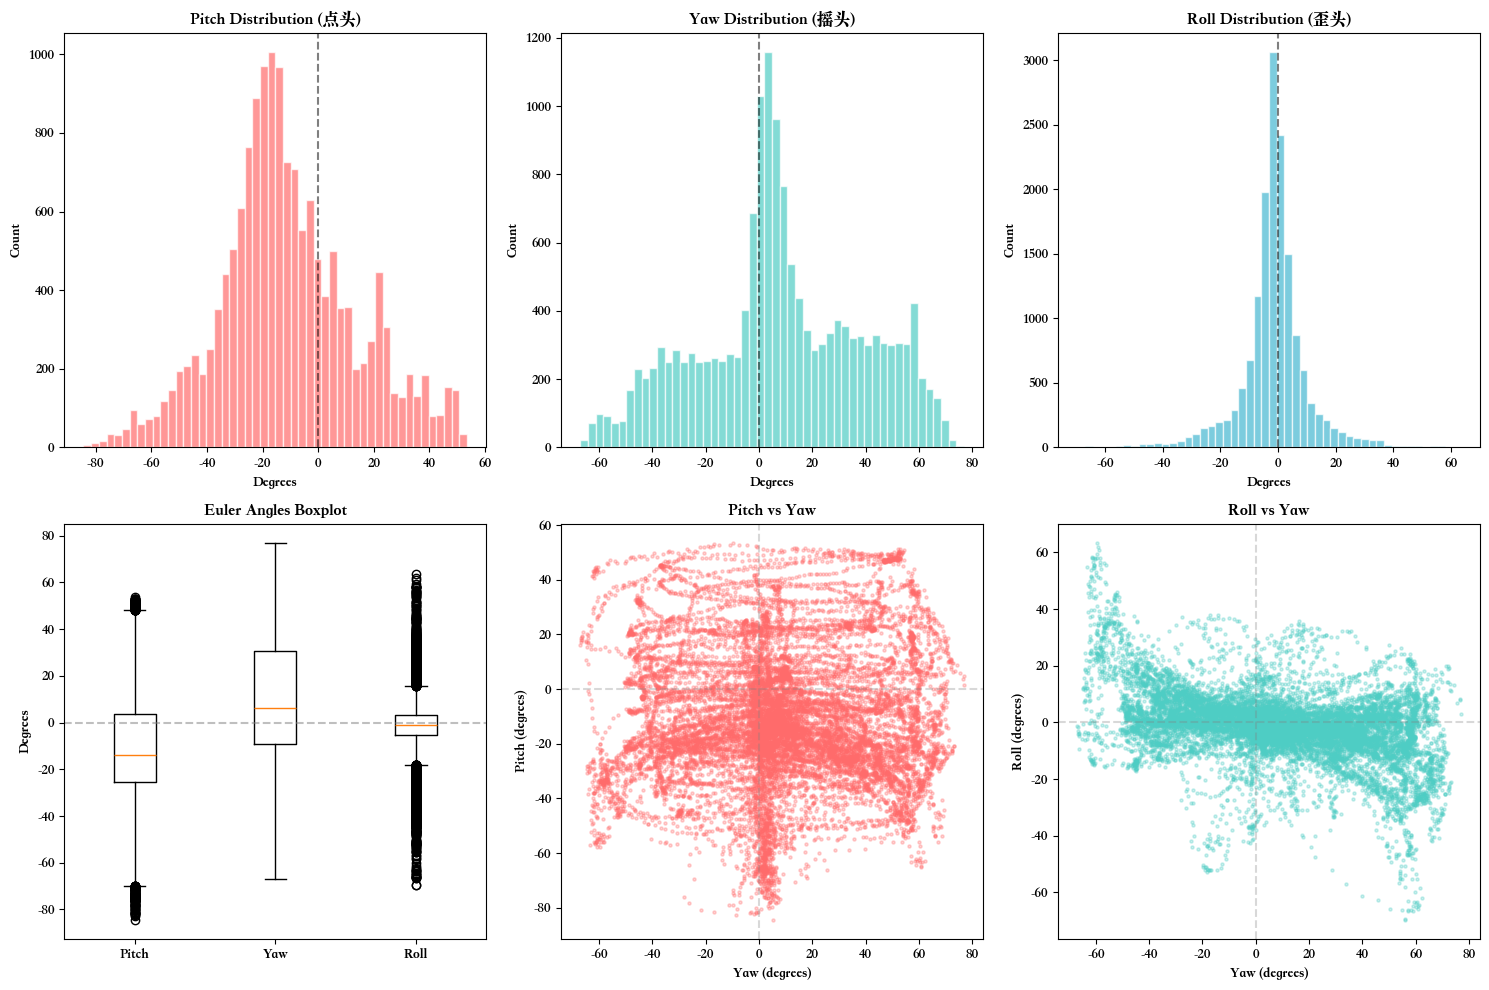


图表已保存为 euler_angles_distribution.png


In [15]:
# 可视化欧拉角分布
if len(pitches) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # 设置颜色
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
    
    # 第一行：直方图
    axes[0, 0].hist(pitches, bins=50, color=colors[0], alpha=0.7, edgecolor='white')
    axes[0, 0].set_title('Pitch Distribution (点头)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Degrees')
    axes[0, 0].set_ylabel('Count')
    axes[0, 0].axvline(x=0, color='black', linestyle='--', alpha=0.5)
    
    axes[0, 1].hist(yaws, bins=50, color=colors[1], alpha=0.7, edgecolor='white')
    axes[0, 1].set_title('Yaw Distribution (摇头)', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Degrees')
    axes[0, 1].set_ylabel('Count')
    axes[0, 1].axvline(x=0, color='black', linestyle='--', alpha=0.5)
    
    axes[0, 2].hist(rolls, bins=50, color=colors[2], alpha=0.7, edgecolor='white')
    axes[0, 2].set_title('Roll Distribution (歪头)', fontsize=12, fontweight='bold')
    axes[0, 2].set_xlabel('Degrees')
    axes[0, 2].set_ylabel('Count')
    axes[0, 2].axvline(x=0, color='black', linestyle='--', alpha=0.5)
    
    # 第二行：箱线图和2D散点图
    axes[1, 0].boxplot([pitches, yaws, rolls], labels=['Pitch', 'Yaw', 'Roll'])
    axes[1, 0].set_title('Euler Angles Boxplot', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Degrees')
    axes[1, 0].axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    
    # Pitch vs Yaw 散点图
    axes[1, 1].scatter(yaws, pitches, alpha=0.3, s=5, c=colors[0])
    axes[1, 1].set_xlabel('Yaw (degrees)')
    axes[1, 1].set_ylabel('Pitch (degrees)')
    axes[1, 1].set_title('Pitch vs Yaw', fontsize=12, fontweight='bold')
    axes[1, 1].axhline(y=0, color='gray', linestyle='--', alpha=0.3)
    axes[1, 1].axvline(x=0, color='gray', linestyle='--', alpha=0.3)
    
    # Yaw vs Roll 散点图
    axes[1, 2].scatter(yaws, rolls, alpha=0.3, s=5, c=colors[1])
    axes[1, 2].set_xlabel('Yaw (degrees)')
    axes[1, 2].set_ylabel('Roll (degrees)')
    axes[1, 2].set_title('Roll vs Yaw', fontsize=12, fontweight='bold')
    axes[1, 2].axhline(y=0, color='gray', linestyle='--', alpha=0.3)
    axes[1, 2].axvline(x=0, color='gray', linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('euler_angles_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("\n图表已保存为 euler_angles_distribution.png")
else:
    print("没有足够的数据进行可视化")


## 4. 样本图像可视化


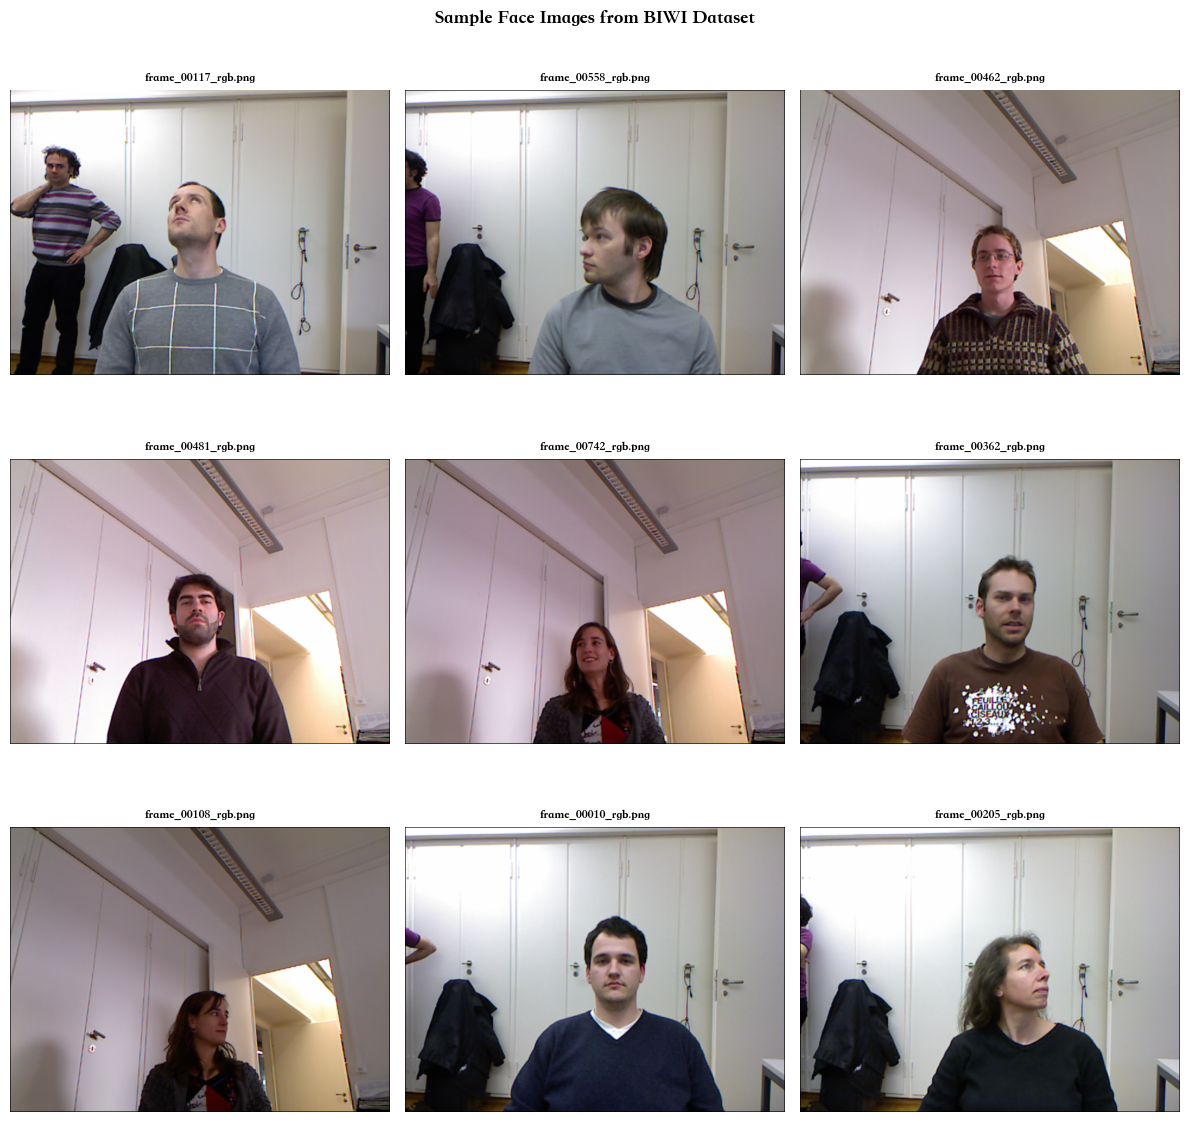


共 15678 张图像，已随机展示 9 张样本


In [16]:
# 可视化样本图像
faces_dir = os.path.join(DATASET_ROOT, "faces_0")

if os.path.exists(faces_dir):
    # 收集所有图像
    image_files = []
    image_extensions = {'.jpg', '.jpeg', '.png', '.bmp'}
    
    for root, dirs, files in os.walk(faces_dir):
        for f in files:
            if os.path.splitext(f)[1].lower() in image_extensions:
                image_files.append(os.path.join(root, f))
    
    if image_files:
        # 随机选择9张图像
        np.random.seed(42)
        sample_indices = np.random.choice(len(image_files), min(9, len(image_files)), replace=False)
        sample_images = [image_files[i] for i in sample_indices]
        
        fig, axes = plt.subplots(3, 3, figsize=(12, 12))
        axes = axes.flatten()
        
        for idx, img_path in enumerate(sample_images):
            img = cv2.imread(img_path)
            if img is not None:
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                axes[idx].imshow(img_rgb)
                axes[idx].set_title(os.path.basename(img_path)[:20], fontsize=9)
                axes[idx].axis('off')
            else:
                axes[idx].text(0.5, 0.5, 'Load Error', ha='center', va='center')
                axes[idx].axis('off')
        
        # 隐藏多余的子图
        for idx in range(len(sample_images), 9):
            axes[idx].axis('off')
        
        plt.suptitle('Sample Face Images from BIWI Dataset', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig('sample_faces.png', dpi=150, bbox_inches='tight')
        plt.show()
        
        print(f"\n共 {len(image_files)} 张图像，已随机展示 {len(sample_images)} 张样本")
    else:
        print("未找到图像文件")
else:
    print("faces_0 目录不存在!")


## 5. 数据质量检查与总结


In [18]:
# 数据完整性检查
print("=" * 60)
print("BIWI Dataset Summary Report")
print("=" * 60)

# 检查各目录
directories = {
    'db_annotations': os.path.join(DATASET_ROOT, "db_annotations"),
    'faces_0': os.path.join(DATASET_ROOT, "faces_0"),
    'head_pose_masks': os.path.join(DATASET_ROOT, "head_pose_masks")
}

total_files = {}
for name, path in directories.items():
    if os.path.exists(path):
        count = sum([len(files) for _, _, files in os.walk(path)])
        total_files[name] = count
        print(f"\n{name}:")
        print(f"  状态: ✅ 存在")
        print(f"  文件数: {count}")
    else:
        total_files[name] = 0
        print(f"\n{name}:")
        print(f"  状态: ❌ 不存在")

# 数据匹配检查
print("\n" + "-" * 60)
print("数据匹配分析:")
print("-" * 60)

# BIWI数据集结构：每个样本包含多种文件类型
# - db_annotations: pose.bin 文件 (每帧1个)
# - faces_0: 可能包含 RGB图、深度图、掩码等 (每帧多个)
# - head_pose_masks: 掩码文件

if total_files.get('db_annotations', 0) > 0 and total_files.get('faces_0', 0) > 0:
    ratio = total_files['faces_0'] / total_files['db_annotations']
    print(f"图像/标注比例: {ratio:.2f}")
    
    # BIWI每个pose对应多种图像(RGB + Depth + Mask等)，比例通常是2-3倍
    if 0.9 <= ratio <= 1.1:
        print("✅ 1:1 匹配 - 每个标注对应1张图像")
    elif 1.9 <= ratio <= 2.1:
        print("✅ 2:1 匹配 - 每个标注对应2种图像 (如 RGB + Depth)")
    elif 2.9 <= ratio <= 3.1:
        print("✅ 3:1 匹配 - 每个标注对应3种图像 (如 RGB + Depth + Mask)")
    else:
        print(f"⚠️ 比例为 {ratio:.2f}，需要进一步检查文件结构")
    
    # 计算估计的样本数
    estimated_samples = total_files['db_annotations']
    print(f"\n估计总样本数: {estimated_samples} 帧")

# 数据质量评估
print("\n" + "-" * 60)
print("数据质量评估:")
print("-" * 60)

if len(pitches) > 0:
    # 检查异常值
    pitch_outliers = np.sum(np.abs(pitches) > 90)
    yaw_outliers = np.sum(np.abs(yaws) > 90)
    roll_outliers = np.sum(np.abs(rolls) > 90)
    
    print(f"Pitch 异常值 (|angle| > 90°): {pitch_outliers} ({100*pitch_outliers/len(pitches):.2f}%)")
    print(f"Yaw 异常值 (|angle| > 90°): {yaw_outliers} ({100*yaw_outliers/len(yaws):.2f}%)")
    print(f"Roll 异常值 (|angle| > 90°): {roll_outliers} ({100*roll_outliers/len(rolls):.2f}%)")
    
    # 角度覆盖范围
    print("\n角度覆盖范围:")
    print(f"  Pitch: {pitches.min():.1f}° to {pitches.max():.1f}° (range: {pitches.max()-pitches.min():.1f}°)")
    print(f"  Yaw: {yaws.min():.1f}° to {yaws.max():.1f}° (range: {yaws.max()-yaws.min():.1f}°)")
    print(f"  Roll: {rolls.min():.1f}° to {rolls.max():.1f}° (range: {rolls.max()-rolls.min():.1f}°)")

print("\n" + "=" * 60)
print("EDA 完成!")
print("=" * 60)


BIWI Dataset Summary Report

db_annotations:
  状态: ✅ 存在
  文件数: 15677

faces_0:
  状态: ✅ 存在
  文件数: 47107

head_pose_masks:
  状态: ✅ 存在
  文件数: 15677

------------------------------------------------------------
数据匹配分析:
------------------------------------------------------------
图像/标注比例: 3.00
✅ 3:1 匹配 - 每个标注对应3种图像 (如 RGB + Depth + Mask)

估计总样本数: 15677 帧

------------------------------------------------------------
数据质量评估:
------------------------------------------------------------
Pitch 异常值 (|angle| > 90°): 0 (0.00%)
Yaw 异常值 (|angle| > 90°): 0 (0.00%)
Roll 异常值 (|angle| > 90°): 0 (0.00%)

角度覆盖范围:
  Pitch: -84.4° to 53.5° (range: 137.9°)
  Yaw: -67.0° to 76.9° (range: 143.8°)
  Roll: -69.6° to 63.4° (range: 133.0°)

EDA 完成!


## 6. 解析 faces_0 目录下的 pose.txt 文件

发现 `faces_0/` 下存在另一种格式的标注文件 `*_pose.txt`:
- 前3行: 3x3 旋转矩阵 (Rotation Matrix)
- 第4行: 3D 头部中心坐标 (Head Center)


In [19]:
# 解析 faces_0 下的 pose.txt 文件
# 格式: 3x3旋转矩阵 + 3D头部中心

def parse_pose_txt_matrix(pose_file_path):
    """
    解析 faces_0 目录下的 pose.txt 文件
    格式:
        R11 R12 R13
        R21 R22 R23
        R31 R32 R33
        
        tx ty tz
    
    返回: rotation_matrix (3x3), head_center (3,), euler_angles (pitch, yaw, roll in degrees)
    """
    try:
        with open(pose_file_path, 'r') as f:
            lines = [l.strip() for l in f.readlines() if l.strip()]
        
        if len(lines) >= 4:
            # 解析3x3旋转矩阵
            rot_matrix = []
            for i in range(3):
                row = [float(x) for x in lines[i].split()]
                rot_matrix.append(row)
            rot_matrix = np.array(rot_matrix)
            
            # 解析头部中心坐标
            head_center = np.array([float(x) for x in lines[3].split()])
            
            # 从旋转矩阵计算欧拉角
            r = R.from_matrix(rot_matrix)
            euler = r.as_euler('xyz', degrees=True)  # pitch, yaw, roll
            
            return rot_matrix, head_center, euler
        else:
            return None, None, f"Not enough lines: {len(lines)}"
    except Exception as e:
        return None, None, str(e)


# 测试解析 faces_0 下的 pose.txt
print("=" * 60)
print("解析 faces_0 目录下的 pose.txt 文件")
print("=" * 60)

faces_dir = os.path.join(DATASET_ROOT, "faces_0")
pose_txt_files = []

if os.path.exists(faces_dir):
    for root, dirs, files in os.walk(faces_dir):
        for f in files:
            if f.endswith('_pose.txt'):
                pose_txt_files.append(os.path.join(root, f))

print(f"找到 {len(pose_txt_files)} 个 pose.txt 文件")

# 测试解析几个样本
for tf in pose_txt_files[:3]:
    print(f"\n文件: {os.path.relpath(tf, DATASET_ROOT)}")
    print("-" * 50)
    
    # 显示原始内容
    with open(tf, 'r') as f:
        content = f.read()
    print("原始内容:")
    print(content)
    
    # 解析
    rot, center, euler = parse_pose_txt_matrix(tf)
    if rot is not None:
        print(f"✅ 解析成功:")
        print(f"  旋转矩阵:\n{rot}")
        print(f"  头部中心: [{center[0]:.2f}, {center[1]:.2f}, {center[2]:.2f}] mm")
        print(f"\n  欧拉角 (从旋转矩阵计算):")
        print(f"    Pitch: {euler[0]:.2f}°")
        print(f"    Yaw:   {euler[1]:.2f}°")
        print(f"    Roll:  {euler[2]:.2f}°")
    else:
        print(f"❌ 解析失败: {euler}")


解析 faces_0 目录下的 pose.txt 文件
找到 15678 个 pose.txt 文件

文件: faces_0/03/frame_00100_pose.txt
--------------------------------------------------
原始内容:
0.730452 -0.373211 0.571973 
-0.0121179 0.830273 0.557226 
-0.682857 -0.413958 0.601952 

90.2575 4.12036 904.483 


✅ 解析成功:
  旋转矩阵:
[[ 0.730452  -0.373211   0.571973 ]
 [-0.0121179  0.830273   0.557226 ]
 [-0.682857  -0.413958   0.601952 ]]
  头部中心: [90.26, 4.12, 904.48] mm

  欧拉角 (从旋转矩阵计算):
    Pitch: -34.52°
    Yaw:   43.07°
    Roll:  -0.95°

文件: faces_0/03/frame_00366_pose.txt
--------------------------------------------------
原始内容:
0.625667 -0.1599 0.763526 
0.0577597 0.985576 0.159071 
-0.777949 -0.0554246 0.625878 

66.6048 37.4918 884.84 


✅ 解析成功:
  旋转矩阵:
[[ 0.625667  -0.1599     0.763526 ]
 [ 0.0577597  0.985576   0.159071 ]
 [-0.777949  -0.0554246  0.625878 ]]
  头部中心: [66.60, 37.49, 884.84] mm

  欧拉角 (从旋转矩阵计算):
    Pitch: -5.06°
    Yaw:   51.07°
    Roll:  5.27°

文件: faces_0/03/frame_00367_pose.txt
--------------------------------

## 7. 可视化验证 - 在人脸上绘制姿态坐标轴

使用旋转矩阵在人脸图像上绘制 XYZ 坐标轴，验证坐标系解析是否正确：
- **红色 (X轴)**: 指向右侧
- **绿色 (Y轴)**: 指向下方
- **蓝色 (Z轴)**: 指向前方 (从脸部射出)


可视化验证 - 在人脸图像上绘制姿态坐标轴


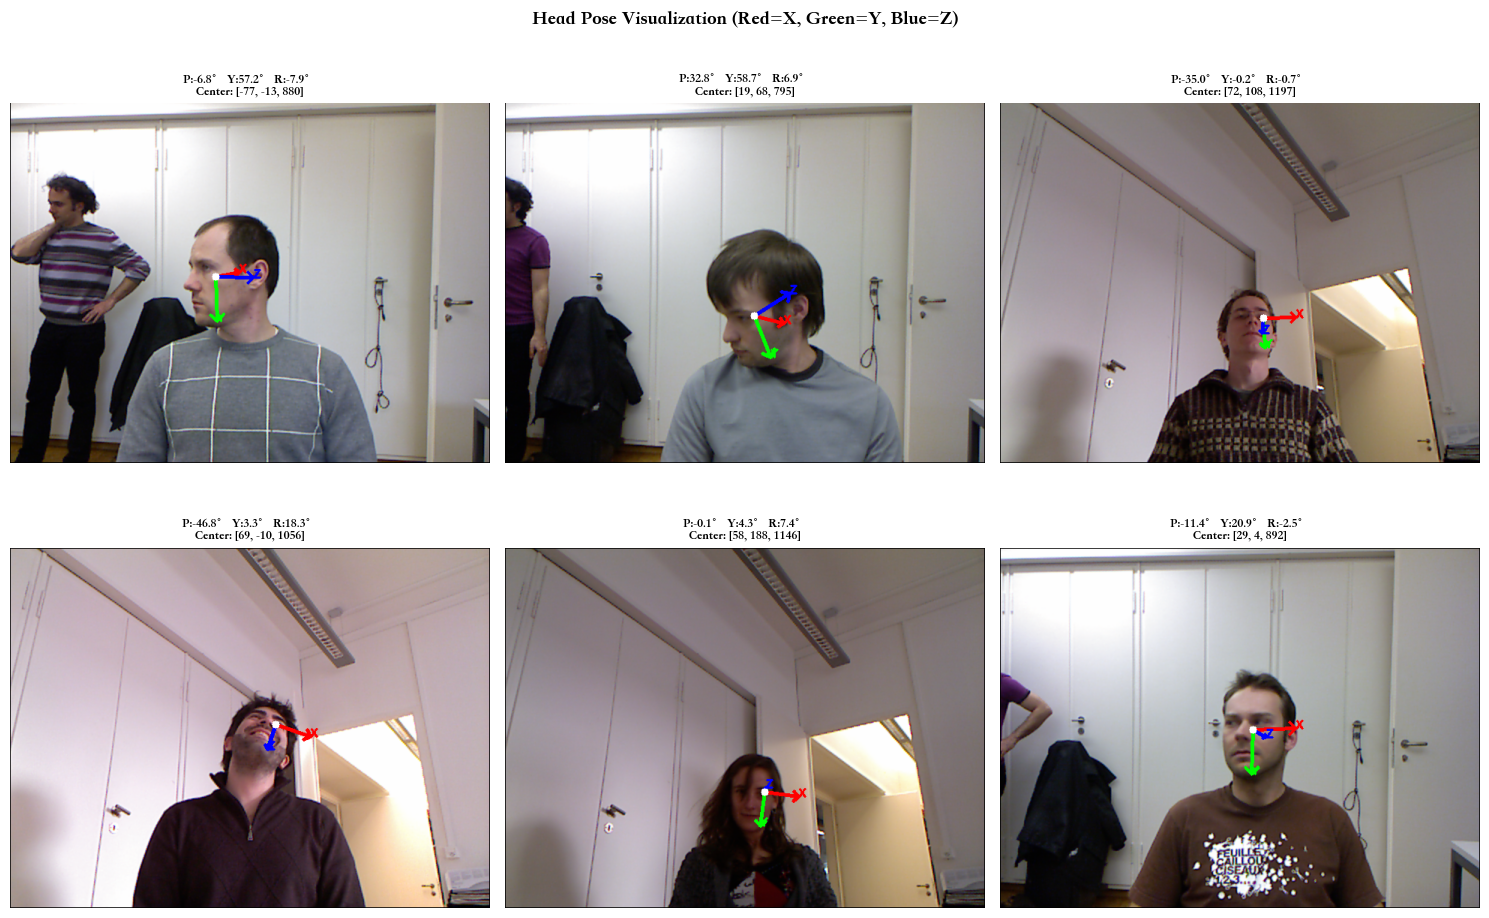


成功可视化 6 个样本
坐标轴说明: 红色=X(右), 绿色=Y(下), 蓝色=Z(前)
图表已保存为 pose_axes_visualization.png


In [20]:
def draw_pose_axes(img, rotation_matrix, head_center, camera_matrix=None, axis_length=100):
    """
    在图像上绘制头部姿态的3D坐标轴
    
    Args:
        img: BGR图像
        rotation_matrix: 3x3 旋转矩阵
        head_center: 头部中心3D坐标 [x, y, z] (mm)
        camera_matrix: 相机内参矩阵 (如果为None则使用默认值)
        axis_length: 坐标轴长度 (mm)
    
    Returns:
        绘制了坐标轴的图像
    """
    img_draw = img.copy()
    h, w = img.shape[:2]
    
    # 默认Kinect相机内参 (根据官方数据)
    # RGB相机: fx=fy=517.679, cx=320, cy=240.5
    if camera_matrix is None:
        camera_matrix = np.array([
            [517.679, 0, 320.0],
            [0, 517.679, 240.5],
            [0, 0, 1]
        ])
    
    # 定义3D坐标轴端点 (相对于头部中心)
    axis_3d = np.array([
        [0, 0, 0],              # 原点
        [axis_length, 0, 0],    # X轴 (红)
        [0, axis_length, 0],    # Y轴 (绿)
        [0, 0, axis_length]     # Z轴 (蓝)
    ], dtype=np.float64)
    
    # 应用旋转
    axis_rotated = (rotation_matrix @ axis_3d.T).T
    
    # 平移到头部中心位置
    axis_world = axis_rotated + head_center
    
    # 投影到2D图像平面
    # 使用针孔相机模型: x' = fx * X/Z + cx, y' = fy * Y/Z + cy
    points_2d = []
    for pt in axis_world:
        if pt[2] > 0:  # 确保在相机前方
            x = camera_matrix[0, 0] * pt[0] / pt[2] + camera_matrix[0, 2]
            y = camera_matrix[1, 1] * pt[1] / pt[2] + camera_matrix[1, 2]
            points_2d.append((int(x), int(y)))
        else:
            points_2d.append(None)
    
    # 绘制坐标轴
    origin = points_2d[0]
    if origin is not None:
        # X轴 - 红色
        if points_2d[1] is not None:
            cv2.arrowedLine(img_draw, origin, points_2d[1], (0, 0, 255), 3, tipLength=0.2)
            cv2.putText(img_draw, 'X', points_2d[1], cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
        
        # Y轴 - 绿色
        if points_2d[2] is not None:
            cv2.arrowedLine(img_draw, origin, points_2d[2], (0, 255, 0), 3, tipLength=0.2)
            cv2.putText(img_draw, 'Y', points_2d[2], cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
        
        # Z轴 - 蓝色
        if points_2d[3] is not None:
            cv2.arrowedLine(img_draw, origin, points_2d[3], (255, 0, 0), 3, tipLength=0.2)
            cv2.putText(img_draw, 'Z', points_2d[3], cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
        
        # 绘制原点
        cv2.circle(img_draw, origin, 5, (255, 255, 255), -1)
    
    return img_draw


def find_matching_rgb_image(pose_txt_path):
    """根据pose.txt路径找到对应的RGB图像"""
    # frame_00216_pose.txt -> frame_00216_rgb.png
    dir_path = os.path.dirname(pose_txt_path)
    base_name = os.path.basename(pose_txt_path)
    frame_prefix = base_name.replace('_pose.txt', '')
    
    # 尝试不同的图像文件名格式
    possible_names = [
        f"{frame_prefix}_rgb.png",
        f"{frame_prefix}_rgb.jpg",
        f"{frame_prefix}.png",
        f"{frame_prefix}.jpg",
    ]
    
    for name in possible_names:
        img_path = os.path.join(dir_path, name)
        if os.path.exists(img_path):
            return img_path
    
    return None


print("=" * 60)
print("可视化验证 - 在人脸图像上绘制姿态坐标轴")
print("=" * 60)

# 随机选择一些样本进行可视化
np.random.seed(42)
sample_pose_files = np.random.choice(pose_txt_files, min(6, len(pose_txt_files)), replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

valid_count = 0
for idx, pose_path in enumerate(sample_pose_files):
    if valid_count >= 6:
        break
        
    # 找到对应的RGB图像
    rgb_path = find_matching_rgb_image(pose_path)
    
    if rgb_path is None:
        print(f"⚠️ 未找到图像: {pose_path}")
        continue
    
    # 读取图像
    img = cv2.imread(rgb_path)
    if img is None:
        print(f"⚠️ 无法读取图像: {rgb_path}")
        continue
    
    # 解析pose
    rot, center, euler = parse_pose_txt_matrix(pose_path)
    if rot is None:
        print(f"⚠️ 无法解析pose: {pose_path}")
        continue
    
    # 绘制坐标轴
    img_with_axes = draw_pose_axes(img, rot, center)
    img_rgb = cv2.cvtColor(img_with_axes, cv2.COLOR_BGR2RGB)
    
    # 显示
    axes[valid_count].imshow(img_rgb)
    axes[valid_count].set_title(
        f"P:{euler[0]:.1f}° Y:{euler[1]:.1f}° R:{euler[2]:.1f}°\n"
        f"Center: [{center[0]:.0f}, {center[1]:.0f}, {center[2]:.0f}]",
        fontsize=9
    )
    axes[valid_count].axis('off')
    valid_count += 1

# 隐藏多余的子图
for idx in range(valid_count, 6):
    axes[idx].axis('off')

plt.suptitle('Head Pose Visualization (Red=X, Green=Y, Blue=Z)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('pose_axes_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n成功可视化 {valid_count} 个样本")
print("坐标轴说明: 红色=X(右), 绿色=Y(下), 蓝色=Z(前)")
print("图表已保存为 pose_axes_visualization.png")


## 8. 对比两种标注格式

BIWI数据集包含两种标注格式:
1. `db_annotations/*.bin` - 6个float: [center_x, center_y, center_z, pitch, yaw, roll]
2. `faces_0/*/_pose.txt` - 3x3旋转矩阵 + 头部中心坐标

让我们验证它们是否一致:


In [21]:
# 对比两种标注格式
print("=" * 60)
print("对比 db_annotations (bin) vs faces_0 (txt) 标注格式")
print("=" * 60)

# 尝试找到对应的bin和txt文件进行比较
annotations_dir = os.path.join(DATASET_ROOT, "db_annotations")
faces_dir = os.path.join(DATASET_ROOT, "faces_0")

comparison_results = []

# 从faces_0中选择一些pose.txt文件
for pose_txt_path in pose_txt_files[:5]:
    # 提取帧ID，例如 faces_0/01/frame_00216_pose.txt -> frame_00216
    base_name = os.path.basename(pose_txt_path)
    frame_id = base_name.replace('_pose.txt', '')
    
    # 查找对应的bin文件 (可能在db_annotations的子目录中)
    bin_file = None
    for root, dirs, files in os.walk(annotations_dir):
        for f in files:
            if frame_id in f and f.endswith('_pose.bin'):
                bin_file = os.path.join(root, f)
                break
        if bin_file:
            break
    
    if bin_file and os.path.exists(bin_file):
        # 解析txt格式
        rot_txt, center_txt, euler_txt = parse_pose_txt_matrix(pose_txt_path)
        
        # 解析bin格式
        rot_bin, center_bin, euler_bin = parse_pose_bin(bin_file)
        
        if rot_txt is not None and isinstance(euler_bin, np.ndarray):
            print(f"\n{frame_id}:")
            print("-" * 50)
            print(f"  pose.txt (旋转矩阵 → 欧拉角):")
            print(f"    Center: [{center_txt[0]:.2f}, {center_txt[1]:.2f}, {center_txt[2]:.2f}]")
            print(f"    Euler:  P={euler_txt[0]:.2f}°, Y={euler_txt[1]:.2f}°, R={euler_txt[2]:.2f}°")
            
            print(f"  pose.bin (直接存储):")
            print(f"    Center: [{center_bin[0]:.2f}, {center_bin[1]:.2f}, {center_bin[2]:.2f}]")
            print(f"    Euler:  P={euler_bin[0]:.2f}°, Y={euler_bin[1]:.2f}°, R={euler_bin[2]:.2f}°")
            
            # 计算差异
            center_diff = np.linalg.norm(center_txt - center_bin)
            euler_diff = np.abs(euler_txt - euler_bin)
            
            print(f"  差异:")
            print(f"    Center距离: {center_diff:.4f} mm")
            print(f"    Euler差异:  P={euler_diff[0]:.4f}°, Y={euler_diff[1]:.4f}°, R={euler_diff[2]:.4f}°")
            
            comparison_results.append({
                'frame': frame_id,
                'center_diff': center_diff,
                'euler_diff': euler_diff
            })

if comparison_results:
    print("\n" + "=" * 60)
    print("对比结论:")
    print("=" * 60)
    avg_center_diff = np.mean([r['center_diff'] for r in comparison_results])
    avg_euler_diff = np.mean([np.mean(r['euler_diff']) for r in comparison_results])
    print(f"平均 Center 差异: {avg_center_diff:.4f} mm")
    print(f"平均 Euler 差异: {avg_euler_diff:.4f}°")
    
    if avg_center_diff < 1 and avg_euler_diff < 1:
        print("✅ 两种格式基本一致!")
    else:
        print("⚠️ 两种格式存在显著差异，需要进一步检查")
else:
    print("\n未找到可对比的文件对，可能目录结构不同")
    print("建议: 检查 db_annotations 和 faces_0 的目录结构")


对比 db_annotations (bin) vs faces_0 (txt) 标注格式

frame_00100:
--------------------------------------------------
  pose.txt (旋转矩阵 → 欧拉角):
    Center: [90.26, 4.12, 904.48]
    Euler:  P=-34.52°, Y=43.07°, R=-0.95°
  pose.bin (直接存储):
    Center: [90.26, 4.12, 904.48]
    Euler:  P=-34.52°, Y=43.07°, R=-0.95°
  差异:
    Center距离: 0.0000 mm
    Euler差异:  P=0.0000°, Y=0.0000°, R=0.0000°

frame_00366:
--------------------------------------------------
  pose.txt (旋转矩阵 → 欧拉角):
    Center: [66.60, 37.49, 884.84]
    Euler:  P=-5.06°, Y=51.07°, R=5.27°
  pose.bin (直接存储):
    Center: [66.60, 37.49, 884.84]
    Euler:  P=-5.06°, Y=51.07°, R=5.27°
  差异:
    Center距离: 0.0000 mm
    Euler差异:  P=0.0000°, Y=0.0000°, R=0.0000°

frame_00367:
--------------------------------------------------
  pose.txt (旋转矩阵 → 欧拉角):
    Center: [68.30, 36.55, 883.20]
    Euler:  P=-5.58°, Y=49.58°, R=4.64°
  pose.bin (直接存储):
    Center: [68.30, 36.55, 883.20]
    Euler:  P=-5.58°, Y=49.58°, R=4.64°
  差异:
    Center距离: 0.0